# 3.4 MLP + Attention over Click History

**What this notebook does.** It takes the MLP from `3.3_mlp_model_improved.ipynb` and adds one thing: an **attention block** that builds a different picture of the user for every article being scored.

**Why.** In Notebook 3.3, a user is described by one fixed vector: the average of every article they have clicked. If someone reads half football and half cooking, their average sits somewhere in between, and that same blurred vector is used for a football article and a cooking article alike. With attention, when the model scores a football article it looks back at the user's clicks, gives more weight to the football ones, and builds the user vector from those. When it scores a cooking article, it leans on the cooking clicks instead.

**How the MLP notebooks fit together**

| Notebook | What it adds |
|---|---|
| 3.1 | Feature engineering (features, split, negative sampling) |
| 3.2 | Feature-rich MLP |
| 3.3 | Same MLP, trained with cold-user simulation; ablation drops `habit_score` and `diversity_ratio` |
| **3.4** | **3.3 + attention over the user's last 50 clicks** (this notebook) |

**Model names in the outputs.** `mlp_3.3` is Notebook 3.3's model re-trained here under the same conditions; `mlp_attn` is the same model with attention; `popularity_ctr` ranks by click rate on earlier days.

**What is copied and what is new.** Sections 1, 2, 4, 5.1 and 6 are copied from 3.3 so that the baseline here is exactly 3.3's model. The new parts are Section 3 (reading each user's click list), Section 5.2–5.3 (the attention block) and Sections 7–9 (training, results, diagnostics).


## 0. Setup
### 0.1 Libraries

In [1]:
import os, json, time, copy, random
import numpy as np
import pandas as pd
from scipy.stats import rankdata
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as Fnn
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Running on:', device)

Running on: cuda


### 0.2 Folders
The folder in your Google Drive that holds the raw MIND data and Notebook 3.1's output. It must be the same folder Notebook 3.1 writes to (the group's notebooks use `Y4S1/BT4222`).

In [2]:
DRIVE_FOLDER = 'Y4S1/BT4222'   # group folder (same as Notebook 3.1); this run used 'BT4222'

BASE = os.environ.get('BT4222_BASE')        # only used when running outside Colab
if BASE is None:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = os.path.join('/content/drive/MyDrive', DRIVE_FOLDER, '')

MIND_DIR = BASE                                 # raw MIND: MINDsmall_train/ and MINDsmall_dev/  (= DATA_ROOT in 3.1)
FEATURE_DIR = os.path.join(BASE, 'MLP/')        # features made by 3.1                         (= OUT_DIR in 3.1)
OUT_DIR = os.path.join(BASE, 'mlp_attn_out/')   # results of this notebook
os.makedirs(OUT_DIR, exist_ok=True)

print('Raw MIND :', MIND_DIR)
print('Features :', FEATURE_DIR)
print('Outputs  :', OUT_DIR)

Mounted at /content/drive
Raw MIND : /content/drive/MyDrive/BT4222/
Features : /content/drive/MyDrive/BT4222/MLP/
Outputs  : /content/drive/MyDrive/BT4222/mlp_attn_out/


### 0.3 Settings
The first block is identical to Notebook 3.3, so the only difference between the two models trained here is the attention block. The second block holds the new settings.

In [3]:
# Same as 3.3
SEED = 42
EMBED_DIM = 64                  # every input block is projected to 64 numbers
CAT_DIM = 32                    # size of the category / subcategory embeddings
HIDDEN = [128, 64, 32]          # layers of the scoring MLP
DROPOUT = 0.2
ID_DROPOUT = 0.1                # randomly hides an article's subcategory during training
LR = 1e-3
WEIGHT_DECAY = 1e-5
BATCH_SIZE = 32                 # impressions per training batch (1 click + 4 skipped articles each)
MAX_EPOCHS = 8
PATIENCE = 2                    # stop after 2 epochs without a better validation nDCG@5
COLD_SIM_RATE = 0.15            # share of warm users shown as cold users during training
DROP_FEATURES = ['diversity_ratio', 'habit_score']   # dropped by 3.3's ablation (config 'no_optional')
NDCG_KS, RECALL_KS = (5, 10), (5, 10)

# New in 3.4
HIST_LEN = 50                   # how many of the user's most recent clicks the attention looks at
ATT_HIDDEN = 32                 # size of the small network that scores "how related is this click?"
EVAL_ROWS = 8192                # candidates per evaluation batch (keeps memory low on long slates)

SPLITS = ['train', 'val', 'test']
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.width', 200)

### 0.4 Raw MIND-small
MIND-small is distributed through Hugging Face (linked from msnews.github.io): https://huggingface.co/datasets/yjw1029/MIND. It is gated, so log in, accept the license, download `MINDsmall_train.zip` and `MINDsmall_dev.zip`, and put both zips in the Drive folder from 0.2. This cell unzips them (or downloads them if you paste a Hugging Face read token into `HF_TOKEN`). Folders that are already unzipped are skipped.

In [4]:
HF_TOKEN = ''

def find_dir(root, name):
    """Find a sub-folder by name anywhere under root (same helper as 3.1)."""
    if os.path.isdir(os.path.join(root, name)):
        return os.path.join(root, name)
    for dirpath, dirnames, _ in os.walk(root):
        if name in dirnames:
            return os.path.join(dirpath, name)
    raise FileNotFoundError(f'{name} not found under {root}')


import zipfile
for name in ['MINDsmall_train', 'MINDsmall_dev']:
    try:
        print(name, 'already in', find_dir(MIND_DIR, name))
        continue
    except FileNotFoundError:
        pass
    zip_path = os.path.join(MIND_DIR, name + '.zip')
    if not os.path.exists(zip_path) and HF_TOKEN:
        from huggingface_hub import hf_hub_download
        print('Downloading', name, 'from Hugging Face ...')
        zip_path = hf_hub_download('yjw1029/MIND', name + '.zip', repo_type='dataset', token=HF_TOKEN, local_dir='/content/mind_zips')
    if not os.path.exists(zip_path):
        print(f'{name}: not found. Upload {name}.zip into {MIND_DIR} or set HF_TOKEN (see the note above).')
        continue
    zf = zipfile.ZipFile(zip_path)
    # unzip into <folder>/ unless the zip already contains that folder
    target = MIND_DIR if all(n.startswith(name + '/') for n in zf.namelist()) else os.path.join(MIND_DIR, name)
    zf.extractall(target)
    print(name, 'unzipped:', sorted(os.listdir(find_dir(MIND_DIR, name))))

MINDsmall_train already in /content/drive/MyDrive/BT4222/MINDsmall_train
MINDsmall_dev already in /content/drive/MyDrive/BT4222/MINDsmall_dev


## 1. Load the features from Notebook 3.1

| File from 3.1 | What it holds |
|---|---|
| `articles.parquet` | one row per article: id, category, subcategory, has-entity flag |
| `article_content_emb.npy` | MiniLM text vector (384 numbers) per article |
| `kg_entity_emb.npy` | knowledge-graph entity vector (100 numbers) per article |
| `user_profiles.parquet` | one row per distinct click history: length, entropy, ... |
| `user_history_emb.npy` | the user's average clicked-article vector (3.3's fixed user vector) |
| `user_category_affinity.npy` | share of the user's clicks in each category |
| `{split}_impressions / groups / candidates.parquet` | the impressions, and the candidate articles with their features |
| `feature_meta.json` | feature lists, split definition, training means for missing values |

In [5]:
def load_table(name):
    path = os.path.join(FEATURE_DIR, name)
    return pd.read_parquet(path + '.parquet') if os.path.exists(path + '.parquet') else pd.read_pickle(path + '.pkl')


with open(os.path.join(FEATURE_DIR, 'feature_meta.json')) as f:
    meta = json.load(f)
N_ART, N_CAT, N_SUBCAT = meta['dims']['n_articles'], meta['dims']['n_cat'], meta['dims']['n_subcat']
SPARSE_MAX = meta['cold_start']['sparse_user_max']        # users with 1..SPARSE_MAX-1 clicks are "sparse"

# Articles: lookup tables indexed by news_idx (row 0 = padding)
articles = load_table('articles')
content_emb = np.load(os.path.join(FEATURE_DIR, 'article_content_emb.npy')).astype(np.float32)
kg_emb = np.load(os.path.join(FEATURE_DIR, 'kg_entity_emb.npy')).astype(np.float32)
has_kg = np.zeros(N_ART, np.float32);    has_kg[articles.news_idx.values] = articles.has_kg_entity.values
art_cat = np.zeros(N_ART, np.int64);     art_cat[articles.news_idx.values] = articles.category_idx.values
art_subcat = np.zeros(N_ART, np.int64);  art_subcat[articles.news_idx.values] = articles.subcategory_idx.values
news_ids = np.empty(N_ART, dtype=object); news_ids[0] = '<PAD>'; news_ids[articles.news_idx.values] = articles.news_id.values

print('articles             :', len(articles))
print('text vectors         :', content_emb.shape)
print('entity vectors       :', kg_emb.shape)

articles             : 65238
text vectors         : (65239, 384)
entity vectors       : (65239, 100)


In [6]:
# Users: one row per distinct click history (profile_idx 0 = no history)
profiles = load_table('user_profiles').sort_values('profile_idx').reset_index(drop=True)
user_emb = np.load(os.path.join(FEATURE_DIR, 'user_history_emb.npy')).astype(np.float32)
user_aff = np.load(os.path.join(FEATURE_DIR, 'user_category_affinity.npy')).astype(np.float32)

print('user profiles        :', len(profiles))
print('average user vectors :', user_emb.shape)
print('category affinities  :', user_aff.shape)

user profiles        : 91359
average user vectors : (91359, 384)
category affinities  : (91359, 19)


In [7]:
# Impressions and candidates for each split
data = {s: {'imp': load_table(f'{s}_impressions'),
            'groups': load_table(f'{s}_groups'),
            'cands': load_table(f'{s}_candidates')} for s in SPLITS}

for s in SPLITS:
    days = sorted(int(x) for x in data[s]['imp'].day.unique())
    print(f"{s:5s}: {len(data[s]['groups']):>8,} impressions | {len(data[s]['cands']):>10,} candidates | days {days}")
print('Split:', meta['split']['scheme'])
print('Training negatives:', meta['negative_sampling']['train'])

train:  189,519 impressions |    906,625 candidates | days [0, 1, 2, 3, 4]
val  :   30,270 impressions |  1,222,429 candidates | days [5]
test :   73,152 impressions |  2,740,998 candidates | days [6]
Split: 5-1-1 by calendar day
Training negatives: per positive, up to 4 negatives from same impression, no replacement, seed 42; short groups masked (no repeats); impressions without negatives dropped


## 2. Prepare the inputs (copied from Notebook 3.3)
### 2.1 Feature lists
The feature lists come from 3.1. We use 3.3's selected configuration: every feature group on, `diversity_ratio` and `habit_score` dropped. The assert checks the model contract: none of the excluded features (`slate_length`, `article_recency`, `session_dow`) is used.

In [8]:
F = meta['features']
POP_COLS = F['popularity']                          # article popularity on earlier days
INTER_COLS = F['user_x_article']                    # how well the article matches the user
CAND_COLS = POP_COLS + INTER_COLS
USER_COLS = F['user']['scalar'] + F['optional']['user']
CTX_COLS = F['context'] + F['optional']['context']  # time of day
BINARY = {'is_cold_article', 'category_match', 'has_history'}

used = set(CAND_COLS + USER_COLS + CTX_COLS) | {'article_content_emb', 'kg_entity_emb', 'category_idx', 'subcategory_idx'}
assert not used & set(meta['excluded_features']), 'model contract: an excluded feature is in use'

USE_GROUPS = {'article': True, 'popularity': True, 'user': True, 'user_x_article': True, 'context': True}


def make_config(name, groups=None, drop=()):
    return {'name': name, 'groups': dict(groups or USE_GROUPS), 'drop': sorted(set(drop))}


def active_features(cfg):
    keep = lambda cols: [c for c in cols if c not in cfg['drop']]
    g = cfg['groups']
    return {'popularity': keep(POP_COLS) if g['popularity'] else [],
            'user_x_article': keep(INTER_COLS) if g['user_x_article'] else [],
            'user': keep(USER_COLS) if g['user'] else [],
            'context': keep(CTX_COLS) if g['context'] else []}


CFG = make_config('no_optional', USE_GROUPS, drop=DROP_FEATURES)
for block, cols in active_features(CFG).items():
    print(f'{block:15s}: {cols}')

popularity     : ['hist_ctr', 'log_exposure', 'is_cold_article']
user_x_article : ['category_match', 'cos_user_hist', 'max_cos_hist', 'cos_last5', 'cat_affinity', 'kg_match']
user           : ['log_history_length', 'has_history', 'reading_entropy']
context        : ['hour_sin', 'hour_cos']


### 2.2 Standardise with training statistics
Continuous features are scaled with the **training** mean and standard deviation only (no information from validation or test). 0/1 flags are left as they are.

In [9]:
tr_cands = data['train']['cands']
tr_prof = data['train']['imp'].set_index('impression_id').loc[data['train']['groups'].impression_id, 'profile_idx'].values

cand_mu = {c: 0.0 if c in BINARY else float(tr_cands[c].mean()) for c in CAND_COLS}
cand_sd = {c: 1.0 if c in BINARY else float(tr_cands[c].std() or 1.0) for c in CAND_COLS}
user_mu = {c: 0.0 if c in BINARY else float(profiles[c].values[tr_prof].mean()) for c in USER_COLS}
user_sd = {c: 1.0 if c in BINARY else float(profiles[c].values[tr_prof].std() or 1.0) for c in USER_COLS}
ctx_mu = {c: float(data['train']['imp'][c].mean()) if c == 'habit_score' else 0.0 for c in CTX_COLS}
ctx_sd = {c: float(data['train']['imp'][c].std() or 1.0) if c == 'habit_score' else 1.0 for c in CTX_COLS}

user_x_all = np.stack([(profiles[c].values - user_mu[c]) / user_sd[c] for c in USER_COLS], 1).astype(np.float32)
print('standardised user features:', user_x_all.shape)

standardised user features: (91359, 4)


### 2.3 Turn each split into flat arrays
Every candidate of every impression goes into one long array; `start[g]` and `n[g]` say where impression `g` begins and how many candidates it has. Training impressions have 5 candidates (1 click + 4 skipped); validation and test keep the full slate.

In [10]:
def assemble(split):
    d = data[split]
    g = d['groups'].sort_values('group_id').reset_index(drop=True)
    c = d['cands'].sort_values(['group_id', 'slot']).reset_index(drop=True)
    imp = d['imp'].set_index('impression_id').loc[g.impression_id]
    start = np.concatenate([[0], np.cumsum(g.n_cand.values)[:-1]]).astype(np.int64)
    assert len(c) == g.n_cand.sum() and (c.group_id.values == np.repeat(g.group_id.values, g.n_cand.values)).all()
    prof = imp['profile_idx'].values.astype(np.int64)
    return {
        'split': split, 'start': start, 'n': g.n_cand.values.astype(np.int64),
        'impression_id': g.impression_id.values, 'user_id': imp['user_id'].values,
        'orig_impression_id': imp['orig_impression_id'].values, 'source': imp['source'].values,
        'hist_len': imp['history_length'].values,
        'news': c.news_idx.values.astype(np.int64), 'label': c.label.values.astype(np.float32),
        'slot': c.slot.values, 'is_cold_article': c.is_cold_article.values.astype(np.int8),
        'cand_x': np.stack([(c[k].values - cand_mu[k]) / cand_sd[k] for k in CAND_COLS], 1).astype(np.float32),
        'prof': prof, 'user_x': user_x_all[prof],
        'ctx_x': np.stack([(imp[k].values - ctx_mu[k]) / ctx_sd[k] for k in CTX_COLS], 1).astype(np.float32),
    }


A = {s: assemble(s) for s in SPLITS}
assert A['train']['n'].max() <= 5

for s in SPLITS:
    hl = A[s]['hist_len']
    print(f"{s:5s}: cold users {np.mean(hl == 0):.2%} | sparse users {np.mean((hl > 0) & (hl < SPARSE_MAX)):.2%} | "
          f"candidates that are cold articles {A[s]['is_cold_article'].mean():.2%}")

train: cold users 1.91% | sparse users 9.57% | candidates that are cold articles 65.21%
val  : cold users 2.55% | sparse users 10.73% | candidates that are cold articles 60.33%
test : cold users 3.03% | sparse users 11.06% | candidates that are cold articles 54.86%


### 2.4 Cold-user simulation inputs
As in 3.3, 15% of warm users in each training batch are shown to the model as if they had no history. Their inputs are replaced with exactly what a real cold user gets: profile 0 and the training-mean match features. Profile 0 also has an **empty click list** (Section 3), so the attention block learns what to do with cold users too.

In [11]:
COLD_PROFILE = 0
assert profiles.loc[COLD_PROFILE, 'history_length'] == 0, 'profile 0 must be the empty-history profile'
COLD_USER_X = user_x_all[COLD_PROFILE].copy()
COLD_INTER = np.array([(meta['imputation_means'][c] - cand_mu[c]) / cand_sd[c] for c in INTER_COLS], np.float32)

tr = A['train']
tr_cold = tr['hist_len'] == 0
if tr_cold.any():
    real_cold_rows = np.repeat(tr_cold, tr['n'])
    assert np.allclose(tr['cand_x'][real_cold_rows][:, len(POP_COLS):], COLD_INTER, atol=1e-4)
    assert np.allclose(tr['user_x'][tr_cold], COLD_USER_X, atol=1e-5)
print('Check passed: simulated cold-user inputs = real cold-user inputs')
print(f'Real cold users in training: {tr_cold.mean():.2%} -> with simulation about '
      f'{tr_cold.mean() + COLD_SIM_RATE * (~tr_cold).mean():.1%} look cold in each epoch')

Check passed: simulated cold-user inputs = real cold-user inputs
Real cold users in training: 1.91% -> with simulation about 16.6% look cold in each epoch


## 3. Each user's click list (new)
3.1 only saved the **average** of each user's clicked articles. Attention needs the **list** of clicked articles, so we rebuild it from the raw MIND data.

* MIND's `history` column lists the articles a user clicked **before** that impression, oldest first. Nothing from the impression itself or later days is in it, so it does not leak the answer. It is the same column 3.1 used for its user features.
* We match every impression to its raw row with `(source, orig_impression_id)`, the two ids 3.1 kept for this.
* In 3.1 a "profile" is one distinct history, so each profile gets one click list: `HIST[profile_idx]` = the last 50 clicked articles (as article numbers), padded with 0.

### 3.1 Read the raw histories

In [12]:
raw = []
for source, folder in [('train', 'MINDsmall_train'), ('dev', 'MINDsmall_dev')]:
    path = os.path.join(find_dir(MIND_DIR, folder), 'behaviors.tsv')
    b = pd.read_csv(path, sep='\t', header=None, usecols=[0, 3], names=['orig_impression_id', 'history'])
    b['source'] = source
    raw.append(b)
raw = pd.concat(raw, ignore_index=True)
raw['history'] = raw['history'].fillna('').str.strip()

print(f'{len(raw):,} raw impressions read')
raw.head(3)

230,117 raw impressions read


,orig_impression_id,history,source
0,1,N55189 N42782 N34694 N45794 N18445 N63302 N104...,train
1,2,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,train
2,3,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,train


### 3.2 Match them to 3.1's impressions

In [13]:
imp_all = pd.concat([data[s]['imp'][['source', 'orig_impression_id', 'profile_idx']] for s in SPLITS])
matched = imp_all.merge(raw, on=['source', 'orig_impression_id'], how='left', validate='many_to_one')

assert matched['history'].notna().all(), 'some impressions were not found in the raw files'
assert matched.groupby('profile_idx')['history'].nunique().max() == 1, 'a profile maps to two different histories'
print(f'All {len(matched):,} impressions matched to their raw history')

All 230,117 impressions matched to their raw history


### 3.3 Build the click-list table `HIST`
One row per profile, 50 columns. Each entry is an article number (`news_idx`), most recent clicks kept, 0 = empty slot. The check at the end confirms that the length of every rebuilt list equals the `history_length` 3.1 computed, so both notebooks agree on what each user clicked.

In [14]:
news_id2idx = dict(zip(articles.news_id, articles.news_idx))

HIST = np.zeros((len(profiles), HIST_LEN), np.int64)
full_len = np.zeros(len(profiles), np.int64)

for p, history in matched.drop_duplicates('profile_idx')[['profile_idx', 'history']].itertuples(index=False):
    ids = [news_id2idx[x] for x in history.split() if x in news_id2idx]
    full_len[p] = len(ids)
    ids = ids[-HIST_LEN:]                     # keep the 50 most recent
    HIST[p, :len(ids)] = ids

seen = np.unique(imp_all.profile_idx.values)
assert (full_len[seen] == profiles.history_length.values[seen]).all(), 'history length differs from 3.1'
assert (HIST[COLD_PROFILE] == 0).all()

hl = A['train']['hist_len']
print('HIST shape:', HIST.shape)
print(f'Training impressions whose whole history fits in {HIST_LEN} clicks: {np.mean(hl <= HIST_LEN):.1%}')
print(f'Median history length: {np.median(hl):.0f} clicks')

HIST shape: (91359, 50)
Training impressions whose whole history fits in 50 clicks: 75.4%
Median history length: 23 clicks


### 3.4 Look at one user
A quick look at what the attention block will see: one training user's most recent clicks, with category and title.

In [15]:
news_raw = pd.concat([
    pd.read_csv(os.path.join(find_dir(MIND_DIR, f), 'news.tsv'), sep='\t', header=None, quoting=3,
                usecols=[0, 1, 3], names=['news_id', 'category', 'title'])
    for f in ['MINDsmall_train', 'MINDsmall_dev']]).drop_duplicates('news_id').set_index('news_id')


def describe(n):
    """'[category] title' for an article number."""
    row = news_raw.loc[news_ids[n]]
    return f"[{row['category']}] {str(row['title'])[:70]}"


example_prof = A['train']['prof'][np.argmax(A['train']['hist_len'] >= 20)]
clicks = HIST[example_prof][HIST[example_prof] > 0]
print(f'Profile {example_prof}: {len(clicks)} clicks in the window. Last 5:')
for n in clicks[-5:]:
    print('  ', describe(n))

Profile 2: 50 clicks in the window. Last 5:
   [news] Air Force airman missing after fall into Gulf of Mexico from C-130 air
   [news] Gunmen kill 15 in southern Thailand's worst attack in years
   [lifestyle] Dad thought he dressed toddler daughter in a hat, but he was hilarious
   [travel] This $12 million 'mansion yacht' is made entirely of stainless steel  
   [music] Dean Martin's Daughter Speaks Out About John Legend's New Version of '


## 4. Evaluation metrics (copied from Notebook 3.3)
Computed per impression over the full slate, then averaged:
* **MRR**: 1 / rank of the first clicked article
* **nDCG@5, nDCG@10**: how high the clicked articles are in the top 5 / 10 (main metric: nDCG@5, the Spotlight size)
* **Recall@5, @10**: share of clicked articles that make the top 5 / 10
* **AUC**: supplementary, chance a clicked article is scored above a skipped one

Slices: `cold_user` (0 clicks), `sparse_user` (1–4 clicks), `warm_user` (5+), `cold_article` (the clicked article had no clicks on earlier days).

In [16]:
METRIC_NAMES = ['AUC', 'MRR'] + [f'nDCG@{k}' for k in NDCG_KS] + [f'Recall@{k}' for k in RECALL_KS]


def impression_metrics(labels, scores):
    order = np.argsort(-scores, kind='stable')
    y = labels[order]
    n_pos = y.sum()
    ranks = np.arange(1, len(y) + 1)
    disc = 1.0 / np.log2(ranks + 1)
    out = {'MRR': float((y / ranks).sum() / n_pos)}
    for k in NDCG_KS:
        ideal = disc[:min(int(n_pos), k)].sum()
        out[f'nDCG@{k}'] = float((y[:k] * disc[:k]).sum() / ideal)
    for k in RECALL_KS:
        out[f'Recall@{k}'] = float(y[:k].sum() / n_pos)
    n_neg = len(y) - n_pos
    if n_neg > 0:
        r = rankdata(scores)
        out['AUC'] = float((r[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))
    else:
        out['AUC'] = np.nan
    return out


def evaluate(Ad, scores):
    """Returns (table of metrics per slice, metrics per impression)."""
    rows, cold_rows = [], []
    for g in range(len(Ad['n'])):
        s, k = Ad['start'][g], Ad['n'][g]
        lab, sc = Ad['label'][s:s+k], scores[s:s+k]
        rows.append(impression_metrics(lab, sc))
        cold = Ad['is_cold_article'][s:s+k] == 1
        cold_pos = (lab == 1) & cold
        if cold_pos.any():
            keep = ~((lab == 1) & ~cold)
            m = impression_metrics(cold_pos[keep].astype(np.float32), sc[keep])
            m['g'] = g
            cold_rows.append(m)
    per_imp = pd.DataFrame(rows)
    hl = Ad['hist_len']
    slices = {'all': np.ones(len(hl), bool), 'cold_user': hl == 0,
              'sparse_user': (hl > 0) & (hl < SPARSE_MAX), 'warm_user': hl >= SPARSE_MAX}
    table = []
    for name, m in slices.items():
        sub = per_imp[m]
        table.append({'slice': name, 'n_impressions': int(m.sum()), 'n_users': int(pd.unique(Ad['user_id'][m]).size),
                      **{k: sub[k].mean() for k in METRIC_NAMES}})
    cold_df = pd.DataFrame(cold_rows)
    n_cold_art_users = int(pd.unique(Ad['user_id'][cold_df['g'].values]).size) if len(cold_df) else 0
    table.append({'slice': 'cold_article', 'n_impressions': len(cold_df), 'n_users': n_cold_art_users,
                  **{k: (cold_df[k].mean() if len(cold_df) else np.nan) for k in METRIC_NAMES}})
    return pd.DataFrame(table), per_imp


# check against a hand-worked example: clicks at ranks 1 and 3 out of 4
m = impression_metrics(np.array([1, 0, 1, 0], np.float32), np.array([0.9, 0.8, 0.7, 0.1]))
assert abs(m['MRR'] - (1 + 1/3) / 2) < 1e-9 and abs(m['AUC'] - 0.75) < 1e-9 and m['Recall@5'] == 1.0
assert abs(m['nDCG@5'] - (1 + 1/np.log2(4)) / (1 + 1/np.log2(3))) < 1e-9
print('Metrics match the hand-worked example')

Metrics match the hand-worked example


## 5. The models
### 5.1 Notebook 3.3's MLP (copied)
Each input group is projected to a 64-number block (`Linear` + `LayerNorm`), the blocks are joined (9 blocks = 576 numbers) and an MLP 128 → 64 → 32 → 1 gives the score. The layers and their order are exactly 3.3's. The only change is that building the blocks is moved into a helper, `blocks()`, so the attention model in 5.3 can reuse it.

In [17]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class Proj(nn.Module):
    """Linear layer + LayerNorm: turns one input group into a 64-number block."""
    def __init__(self, d_in, d_out):
        super().__init__()
        self.lin, self.ln = nn.Linear(d_in, d_out), nn.LayerNorm(d_out)

    def forward(self, x):
        return self.ln(self.lin(x))


def make_head(d_in):
    """The scoring MLP: d_in -> 128 -> 64 -> 32 -> 1 score."""
    layers = []
    for h in HIDDEN:
        layers += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(DROPOUT)]
        d_in = h
    layers.append(nn.Linear(d_in, 1))
    return nn.Sequential(*layers)


class MLPRanker(nn.Module):
    """3.3's model."""
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        g, act = cfg['groups'], active_features(cfg)
        # lookup tables, stored on the GPU with the model
        for name, arr in {'content_emb': content_emb, 'kg_emb': kg_emb, 'has_kg': has_kg, 'art_cat': art_cat,
                          'art_subcat': art_subcat, 'user_emb': user_emb, 'user_aff': user_aff}.items():
            self.register_buffer(name, torch.as_tensor(arr), persistent=False)
        idx = {'pop_idx': [CAND_COLS.index(c) for c in act['popularity']],
               'inter_idx': [CAND_COLS.index(c) for c in act['user_x_article']],
               'user_idx': [USER_COLS.index(c) for c in act['user']],
               'ctx_idx': [CTX_COLS.index(c) for c in act['context']]}
        for name, cols in idx.items():
            self.register_buffer(name, torch.as_tensor(cols, dtype=torch.long), persistent=False)
        self.on = {'article': g['article'], 'popularity': len(idx['pop_idx']) > 0,
                   'user_x_article': len(idx['inter_idx']) > 0, 'user': g['user'],
                   'user_scalar': len(idx['user_idx']) > 0, 'context': len(idx['ctx_idx']) > 0}
        d = EMBED_DIM
        self.cat_emb = nn.Embedding(N_CAT, CAT_DIM, padding_idx=0)
        n_blocks = 0
        if self.on['article']:
            self.subcat_emb = nn.Embedding(N_SUBCAT, CAT_DIM, padding_idx=0)
            self.text_proj = Proj(content_emb.shape[1], d)           # MiniLM text 384 -> 64
            self.kg_proj = Proj(kg_emb.shape[1] + 1, d)              # entities 100 + flag -> 64
            self.cat_proj = Proj(2 * CAT_DIM, d)                     # category + subcategory -> 64
            n_blocks += 3
        if self.on['popularity']:
            self.pop_proj = Proj(len(idx['pop_idx']), d); n_blocks += 1
        if self.on['user']:
            self.user_text_proj = Proj(user_emb.shape[1], d)         # average clicked-article vector -> 64
            self.user_cat_proj = Proj(CAT_DIM, d)                    # category preferences -> 64
            n_blocks += 2
            if self.on['user_scalar']:
                self.user_num_proj = Proj(len(idx['user_idx']), d); n_blocks += 1
        if self.on['user_x_article']:
            self.inter_proj = Proj(len(idx['inter_idx']), d); n_blocks += 1
        if self.on['context']:
            self.ctx_proj = Proj(len(idx['ctx_idx']), d); n_blocks += 1
        self.n_blocks = n_blocks
        self.mlp = make_head(n_blocks * d)

    def _id_dropout(self, idx):
        if self.training and ID_DROPOUT > 0:
            drop = (torch.rand(idx.shape, device=idx.device) < ID_DROPOUT) & (idx > 1)
            idx = idx.masked_fill(drop, 1)
        return idx

    def blocks(self, news, cand_x, prof, user_x, ctx_x):
        """All of 3.3's 64-number input blocks, by name, in 3.3's order."""
        L = news.shape[1]
        per_user = lambda t: t.unsqueeze(1).expand(-1, L, -1)      # same user block for every candidate
        b = {}
        if self.on['article']:
            b['text'] = self.text_proj(self.content_emb[news])
            b['kg'] = self.kg_proj(torch.cat([self.kg_emb[news], self.has_kg[news].unsqueeze(-1)], -1))
            cat, sub = self._id_dropout(self.art_cat[news]), self._id_dropout(self.art_subcat[news])
            b['cat'] = self.cat_proj(torch.cat([self.cat_emb(cat), self.subcat_emb(sub)], -1))
        if self.on['popularity']:
            b['pop'] = self.pop_proj(cand_x.index_select(-1, self.pop_idx))
        if self.on['user_x_article']:
            b['inter'] = self.inter_proj(cand_x.index_select(-1, self.inter_idx))
        if self.on['user']:
            b['user_text'] = per_user(self.user_text_proj(self.user_emb[prof]))
            b['user_cat'] = per_user(self.user_cat_proj(self.user_aff[prof] @ self.cat_emb.weight))
            if self.on['user_scalar']:
                b['user_num'] = per_user(self.user_num_proj(user_x.index_select(-1, self.user_idx)))
        if self.on['context']:
            b['ctx'] = per_user(self.ctx_proj(ctx_x.index_select(-1, self.ctx_idx)))
        return b

    def forward(self, news, mask, cand_x, prof, user_x, ctx_x):
        b = self.blocks(news, cand_x, prof, user_x, ctx_x)
        score = self.mlp(torch.cat(list(b.values()), -1)).squeeze(-1)
        return score.masked_fill(~mask, float('-inf'))         # padded slots never win

### 5.2 The attention block (new)
For one candidate article and the user's past clicks, all already turned into 64-number vectors:

1. **Score each click.** A small network looks at the candidate `q` and one click `k` and outputs a relevance score
   `score(q, k) = w · ReLU(W_q q + W_k k + W_p (q × k) + b)`.
   The `q × k` term (element by element) is large when the two articles share features, which is how "same kind of story" gets a high score. This is the scoring unit from DIN (Deep Interest Network, Zhou et al., 2018). It is learned, not hand-set.
2. **Turn scores into weights.** A softmax over the user's clicks gives weights that add up to 1. Empty slots (padding) get weight 0.
3. **Weighted average.** The user vector for this candidate = Σ weight × click vector.

A user with no clicks gets all-zero weights, so this block is the same constant for every candidate and the model ranks them using its other inputs, as 3.3 does for cold users.

In [18]:
class ClickAttention(nn.Module):
    """Candidate-aware attention over a user's past clicks (DIN-style scoring unit)."""
    def __init__(self, d, hidden):
        super().__init__()
        self.w_q = nn.Linear(d, hidden)                 # looks at the candidate
        self.w_k = nn.Linear(d, hidden, bias=False)     # looks at the past click
        self.w_p = nn.Linear(d, hidden, bias=False)     # looks at candidate x click (shared features)
        self.out = nn.Linear(hidden, 1)                 # -> one relevance score

    def forward(self, q, k, valid):
        """
        q:     candidates   [batch, n_candidates, d]
        k:     past clicks  [batch, n_clicks, d]
        valid: real click?  [batch, n_clicks]  (False = padding)
        returns user vector per candidate [batch, n_candidates, d] and weights [batch, n_candidates, n_clicks]
        """
        q4, k4 = q.unsqueeze(2), k.unsqueeze(1)                          # line candidates up against clicks
        hidden = torch.relu(self.w_q(q4) + self.w_k(k4) + self.w_p(q4 * k4))
        scores = self.out(hidden).squeeze(-1)                            # [batch, n_candidates, n_clicks]
        valid = valid.unsqueeze(1)
        scores = scores.masked_fill(~valid, -1e4)                        # padding -> very low score
        weights = torch.softmax(scores, dim=-1) * valid                  # add up to 1; no clicks -> all 0
        user_vec = weights @ k                                           # weighted average of the clicks
        return user_vec, weights

**Quick check on toy numbers.** One user with 3 real clicks and 2 empty slots, scored against 2 candidates. The block is untrained, so the weights themselves mean nothing yet; this only checks the mechanics: one weight per click, each row adds up to 1, and the empty slots get 0.

In [19]:
torch.manual_seed(0)
toy = ClickAttention(d=8, hidden=4)
q = torch.randn(1, 2, 8)                                 # 2 candidates
k = torch.randn(1, 5, 8)                                 # 5 click slots
valid = torch.tensor([[True, True, True, False, False]])  # last 2 are padding
user_vec, w = toy(q, k, valid)

print('user vector per candidate:', tuple(user_vec.shape))
print('weights (rows = candidates, columns = clicks):')
print(w[0].detach().numpy().round(3))
print('row sums:', w[0].sum(-1).detach().numpy().round(3))

user vector per candidate: (1, 2, 8)
weights (rows = candidates, columns = clicks):
[[0.325 0.388 0.287 0.    0.   ]
 [0.34  0.338 0.322 0.    0.   ]]
row sums: [1. 1.]


### 5.3 3.3's MLP + attention
* Every article (the candidate and each past click) is turned into one 64-number vector the same way, by reusing 3.3's own text and category projections: `article vector = text block + category block`. Using the same encoder for both is what makes a candidate and a past click comparable.
* `ClickAttention` turns the user's last 50 clicks into a user vector for this candidate.
* That vector goes through a `Proj` like every other block and is added as a 10th block, so the scoring MLP sees 640 numbers instead of 576. Everything else, including 3.3's average user vector, stays.

In [20]:
class MLPWithAttention(MLPRanker):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.register_buffer('hist', torch.as_tensor(HIST), persistent=False)   # click list per profile
        self.attention = ClickAttention(EMBED_DIM, ATT_HIDDEN)
        self.user_attn_proj = Proj(EMBED_DIM, EMBED_DIM)
        self.mlp = make_head((self.n_blocks + 1) * EMBED_DIM)                  # one more block

    def encode_article(self, news):
        """Article -> 64 numbers, using 3.3's text and category projections."""
        cat = torch.cat([self.cat_emb(self.art_cat[news]), self.subcat_emb(self.art_subcat[news])], -1)
        return self.text_proj(self.content_emb[news]) + self.cat_proj(cat)

    def click_weights(self, news, prof):
        """Attention weights for candidates `news` and user profiles `prof` (used in Section 9)."""
        clicks = self.hist[prof]
        _, w = self.attention(self.encode_article(news), self.encode_article(clicks), clicks > 0)
        return w

    def forward(self, news, mask, cand_x, prof, user_x, ctx_x):
        b = self.blocks(news, cand_x, prof, user_x, ctx_x)
        clicks = self.hist[prof]                                        # [batch, 50] past clicks
        q = b['text'] + b['cat']                                        # the candidates, encoded
        k = self.encode_article(clicks)                                 # the clicks, encoded the same way
        user_vec, _ = self.attention(q, k, clicks > 0)
        b['user_attn'] = self.user_attn_proj(user_vec)
        score = self.mlp(torch.cat(list(b.values()), -1)).squeeze(-1)
        return score.masked_fill(~mask, float('-inf'))


def build_model(name):
    model = MLPRanker(CFG) if name == 'mlp_3.3' else MLPWithAttention(CFG)
    return model.to(device)


for name in ['mlp_3.3', 'mlp_attn']:
    m = build_model(name)
    print(f'{name:9s}: {sum(p.numel() for p in m.parameters()):>8,} parameters | scoring MLP input = {m.mlp[0].in_features} numbers')
del m

mlp_3.3  :  157,633 parameters | scoring MLP input = 576 numbers
mlp_attn :  176,322 parameters | scoring MLP input = 640 numbers


## 6. Training setup (copied from 3.3)
### 6.1 Batches
`batch_from` pads impressions in a batch to the same length and, during training, applies the cold-user simulation. Setting a user to profile 0 also empties their click list, because `HIST[0]` is all zeros. Evaluation batches are capped at `EVAL_ROWS` candidates (instead of 3.3's fixed number of impressions) so attention fits in memory on long test slates. This only changes how scores are batched, not the scores.

In [21]:
def batch_from(Ad, idx, cold_rate=0.0, rng=None):
    idx = np.asarray(idx)
    n, st = Ad['n'][idx], Ad['start'][idx]
    L = int(n.max())
    pos = np.arange(L)
    valid = pos[None, :] < n[:, None]
    rows = np.where(valid, st[:, None] + pos[None, :], 0)
    cand_x = np.where(valid[..., None], Ad['cand_x'][rows], 0.0).astype(np.float32)
    prof, user_x = Ad['prof'][idx].copy(), Ad['user_x'][idx].copy()
    if cold_rate > 0:
        sim = (rng.random(len(idx)) < cold_rate) & (Ad['hist_len'][idx] > 0)
        prof[sim] = COLD_PROFILE
        user_x[sim] = COLD_USER_X
        cand_x[sim, :, len(POP_COLS):] = COLD_INTER
    to = lambda a, dt=None: torch.as_tensor(a if dt is None else a.astype(dt))
    return {'news': to(np.where(valid, Ad['news'][rows], 0)), 'mask': to(valid),
            'label': to(np.where(valid, Ad['label'][rows], 0.0), np.float32),
            'cand_x': to(cand_x), 'prof': to(prof), 'user_x': to(user_x), 'ctx_x': to(Ad['ctx_x'][idx])}


def train_loader(Ad, seed, cold_rate=COLD_SIM_RATE):
    g = torch.Generator().manual_seed(seed)
    rng = np.random.default_rng(seed + 10_000)
    return DataLoader(np.arange(len(Ad['n'])), batch_size=BATCH_SIZE, shuffle=True, generator=g,
                      collate_fn=lambda idx: batch_from(Ad, idx, cold_rate, rng))


def eval_batches(Ad, max_rows=EVAL_ROWS):
    order = np.argsort(Ad['n'], kind='stable')      # similar slate lengths together -> little padding
    batches, cur = [], []
    for g in order:
        if cur and (len(cur) + 1) * Ad['n'][g] > max_rows:
            batches.append(np.array(cur)); cur = []
        cur.append(g)
    batches.append(np.array(cur))
    return batches

### 6.2 Loss and prediction
**Listwise softmax loss:** within each impression, a softmax over the candidates' scores, and the loss is −log(probability given to the clicked article). The model is rewarded for putting the click above the other articles in the same impression, which is what ranking needs.

In [22]:
def forward(model, b):
    b = {k: v.to(device, non_blocking=True) for k, v in b.items()}
    return model(b['news'], b['mask'], b['cand_x'], b['prof'], b['user_x'], b['ctx_x']), b


def listwise_loss(scores, b):
    logp = Fnn.log_softmax(scores, dim=1).masked_fill(~b['mask'], 0.0)
    return (-(logp * b['label']).sum(1) / b['label'].sum(1).clamp(min=1)).mean()


@torch.no_grad()
def predict(model, Ad):
    """One score per candidate, in the same order as Ad['news']."""
    model.eval()
    out = np.empty(len(Ad['news']), np.float32)
    for idx in eval_batches(Ad):
        s, _ = forward(model, batch_from(Ad, idx))
        s = s.float().cpu().numpy()
        for j, g in enumerate(idx):
            st, k = Ad['start'][g], Ad['n'][g]
            out[st:st + k] = s[j, :k]
    return out

### 6.3 Training loop
Adam, up to 8 epochs. After each epoch the model is scored on the full validation slates; the epoch with the best validation nDCG@5 is kept, and training stops after 2 epochs without improvement. The test set is never used here.

In [23]:
def train_model(name, seed=SEED):
    set_seed(seed)
    model = build_model(name)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history, best, best_state, bad = [], -np.inf, None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); t0 = time.time(); total, count = 0.0, 0
        for b in train_loader(A['train'], seed + epoch):
            scores, b = forward(model, b)
            loss = listwise_loss(scores, b)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b['prof']); count += len(b['prof'])
        val = evaluate(A['val'], predict(model, A['val']))[0].set_index('slice').loc['all']
        history.append({'epoch': epoch, 'train_loss': total / count,
                        **{f'val_{k}': val[k] for k in METRIC_NAMES}, 'seconds': time.time() - t0})
        print(f"  epoch {epoch} | loss {total / count:.4f} | val nDCG@5 {val['nDCG@5']:.4f} | "
              f"val MRR {val['MRR']:.4f} | {time.time() - t0:.0f}s")
        if val['nDCG@5'] > best:
            best, best_state, bad = val['nDCG@5'], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                print('  early stopping')
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


RUN_DIR = os.path.join(OUT_DIR, 'runs')
os.makedirs(RUN_DIR, exist_ok=True)


def train_or_load(name):
    """Train the model, or reload it if this exact run was saved before (e.g. after a Colab disconnect)."""
    settings = json.dumps({'model': name, 'seed': SEED, 'hidden': HIDDEN, 'lr': LR, 'epochs': MAX_EPOCHS,
                           'cold_sim': COLD_SIM_RATE, 'hist_len': HIST_LEN, 'att_hidden': ATT_HIDDEN}, sort_keys=True)
    weights, hist_csv, info = [os.path.join(RUN_DIR, f'{name}.{ext}') for ext in ['pt', 'csv', 'json']]
    if all(os.path.exists(p) for p in [weights, hist_csv, info]) and open(info).read() == settings:
        model = build_model(name)
        model.load_state_dict(torch.load(weights, map_location=device))
        print(f'{name}: reloaded saved run')
        return model, pd.read_csv(hist_csv)
    print(f'Training {name}')
    t0 = time.time()
    model, history = train_model(name)
    torch.save(model.state_dict(), weights)
    history.to_csv(hist_csv, index=False)
    open(info, 'w').write(settings)
    print(f'{name}: done in {(time.time() - t0) / 60:.1f} min')
    return model, history

## 7. Train
Both models use the same seed, data, settings and cold-user simulation. The only difference is the attention block.
### 7.1 Baseline: 3.3's model

In [24]:
baseline, baseline_hist = train_or_load('mlp_3.3')

Training mlp_3.3
  epoch 1 | loss 1.3271 | val nDCG@5 0.3382 | val MRR 0.3112 | 59s
  epoch 2 | loss 1.2928 | val nDCG@5 0.3380 | val MRR 0.3109 | 57s
  epoch 3 | loss 1.2795 | val nDCG@5 0.3336 | val MRR 0.3069 | 58s
  early stopping
mlp_3.3: done in 3.0 min


### 7.2 3.3 + attention

In [25]:
attn_model, attn_hist = train_or_load('mlp_attn')

Training mlp_attn
  epoch 1 | loss 1.3265 | val nDCG@5 0.3349 | val MRR 0.3089 | 76s
  epoch 2 | loss 1.2913 | val nDCG@5 0.3421 | val MRR 0.3151 | 75s
  epoch 3 | loss 1.2778 | val nDCG@5 0.3378 | val MRR 0.3107 | 76s
  epoch 4 | loss 1.2700 | val nDCG@5 0.3324 | val MRR 0.3045 | 76s
  early stopping
mlp_attn: done in 5.1 min


### 7.3 Training curves
Left: training loss (should go down). Right: validation nDCG@5 per epoch; the best epoch is the one kept.

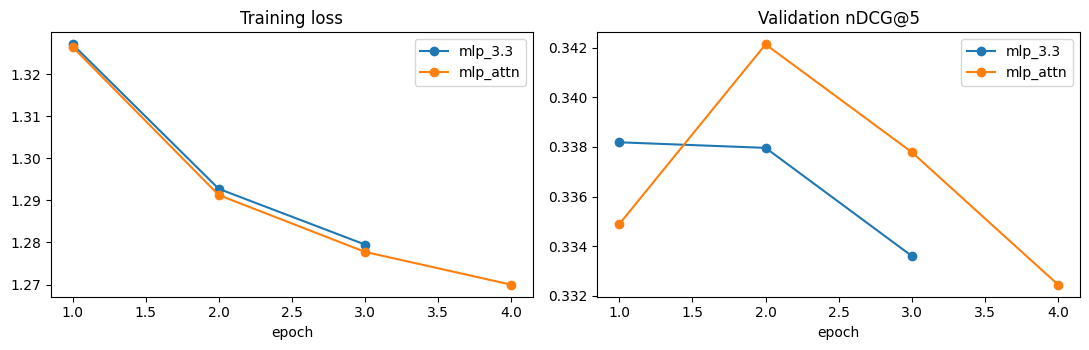

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, h in [('mlp_3.3', baseline_hist), ('mlp_attn', attn_hist)]:
    ax[0].plot(h.epoch, h.train_loss, marker='o', label=name)
    ax[1].plot(h.epoch, h['val_nDCG@5'], marker='o', label=name)
ax[0].set_title('Training loss'); ax[1].set_title('Validation nDCG@5')
for a in ax:
    a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.show()

## 8. Results
### 8.1 Score validation and test
Each model scores every candidate in the full validation and test slates. `popularity_ctr` (rank by click rate on earlier days, no personalisation) is the reference point.

In [27]:
MODELS = {'mlp_3.3': baseline, 'mlp_attn': attn_model}
CTR_COL = CAND_COLS.index('hist_ctr')

scores, per_imp, tables = {}, {}, []
for split in ['val', 'test']:
    for name, model in MODELS.items():
        scores[(name, split)] = predict(model, A[split])
    scores[('popularity_ctr', split)] = A[split]['cand_x'][:, CTR_COL]
    for name in list(MODELS) + ['popularity_ctr']:
        table, per_imp[(name, split)] = evaluate(A[split], scores[(name, split)])
        table.insert(0, 'split', split); table.insert(0, 'model', name)
        tables.append(table)
results = pd.concat(tables, ignore_index=True)
print('Scored:', sorted({k[0] for k in scores}))

Scored: ['mlp_3.3', 'mlp_attn', 'popularity_ctr']


### 8.2 Overall test results
**Main comparison:** `mlp_attn` against `mlp_3.3` on nDCG@5. Both rows use the same test impressions.

In [28]:
cols = ['mlp_3.3', 'mlp_attn', 'popularity_ctr']
overall = results[(results.split == 'test') & (results.slice == 'all')].set_index('model').loc[cols, METRIC_NAMES]
overall

,AUC,MRR,nDCG@5,nDCG@10,Recall@5,Recall@10
model,,,,,,
mlp_3.3,0.6638,0.3194,0.3506,0.4130,0.4894,0.6674
mlp_attn,0.6725,0.3246,0.3575,0.4207,0.4989,0.6789
popularity_ctr,0.5853,0.2673,0.2834,0.3445,0.4069,0.5835


### 8.3 Results by user type (nDCG@5)
Attention needs past clicks to work with, so the gain should show up mostly for `warm_user`. With 0 clicks the block is constant, so `cold_user` should change little.

In [29]:
order = ['all', 'cold_user', 'sparse_user', 'warm_user', 'cold_article']
for split in ['val', 'test']:
    print(f'\n{split} nDCG@5')
    print(results[results.split == split].pivot(index='slice', columns='model', values='nDCG@5').loc[order, cols].to_string())

sizes = results[(results.split == 'test') & (results.model == 'mlp_3.3')][['slice', 'n_impressions', 'n_users']]
print('\nTest impressions / users per slice')
print(sizes.to_string(index=False))


val nDCG@5
model         mlp_3.3  mlp_attn  popularity_ctr
slice                                          
all            0.3382    0.3421          0.2420
cold_user      0.2346    0.2550          0.2435
sparse_user    0.3108    0.3092          0.2720
warm_user      0.3446    0.3488          0.2382
cold_article   0.3752    0.3576          0.1707

test nDCG@5
model         mlp_3.3  mlp_attn  popularity_ctr
slice                                          
all            0.3506    0.3575          0.2834
cold_user      0.2689    0.2660          0.2828
sparse_user    0.3505    0.3565          0.3337
warm_user      0.3535    0.3608          0.2769
cold_article   0.3442    0.3375          0.1444

Test impressions / users per slice
       slice  n_impressions  n_users
         all          73152    50000
   cold_user           2214     1407
 sparse_user           8092     6607
   warm_user          62846    41986
cold_article          42682    32082


### 8.4 Pick the final model (on validation only)
1. The model with the higher **validation** nDCG@5 is kept.
2. For users with **no history**, we check on validation whether plain popularity ranks better than the model. If it does, those users are ranked by popularity (`+ fallback`). 3.3 reported the same fallback as a reference.

Both choices use validation only; the test numbers are just reported afterwards.

In [30]:
val_all = results[(results.split == 'val') & (results.slice == 'all')].set_index('model')['nDCG@5']
BEST = val_all[list(MODELS)].idxmax()

val_cold = results[(results.split == 'val') & (results.slice == 'cold_user')].set_index('model')['nDCG@5']
USE_FALLBACK = bool(val_cold['popularity_ctr'] > val_cold[BEST])
print(f'Best on validation: {BEST}')
print(f"Validation, cold users: {BEST} {val_cold[BEST]:.4f} vs popularity {val_cold['popularity_ctr']:.4f} "
      f"-> fallback {'ON' if USE_FALLBACK else 'OFF'}")

FINAL = BEST + (' + fallback' if USE_FALLBACK else '')
if USE_FALLBACK:
    for split in ['val', 'test']:
        cold_rows = np.repeat(A[split]['hist_len'] == 0, A[split]['n'])
        scores[(FINAL, split)] = np.where(cold_rows, scores[('popularity_ctr', split)], scores[(BEST, split)])
        table, per_imp[(FINAL, split)] = evaluate(A[split], scores[(FINAL, split)])
        table.insert(0, 'split', split); table.insert(0, 'model', FINAL)
        results = pd.concat([results, table], ignore_index=True)

final_test = results[(results.split == 'test') & (results.model == FINAL)].set_index('slice').loc[order, METRIC_NAMES]
print(f'\nFinal model: {FINAL} (test)')
final_test

Best on validation: mlp_attn
Validation, cold users: mlp_attn 0.2550 vs popularity 0.2435 -> fallback OFF

Final model: mlp_attn (test)


,AUC,MRR,nDCG@5,nDCG@10,Recall@5,Recall@10
slice,,,,,,
all,0.6725,0.3246,0.3575,0.4207,0.4989,0.6789
cold_user,0.5681,0.2514,0.2660,0.3316,0.3952,0.5834
sparse_user,0.6214,0.3327,0.3565,0.4188,0.5105,0.6937
warm_user,0.6827,0.3262,0.3608,0.4241,0.5010,0.6804
cold_article,0.6765,0.3107,0.3375,0.3989,0.4862,0.6642


### 8.5 Is the difference real or luck?
A difference of 0.002–0.003 in nDCG@5 can come from which impressions happen to be in the test day. A **paired bootstrap** checks this: resample the test impressions 1,000 times (same impressions for both models) and look at the middle 95% of the difference. If that interval does not include 0, the gain is unlikely to be luck in the test sample.

Limitation: this does not cover training randomness (a different seed gives a slightly different model). Checking that would mean retraining with several seeds.

In [31]:
def paired_bootstrap(a, b, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    diff = (a - b).astype(np.float64)
    boots = np.concatenate([diff[rng.integers(0, len(diff), (100, len(diff)))].mean(1) for _ in range(n_boot // 100)])
    return diff.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


hl = A['test']['hist_len']
groups = {'all': np.ones(len(hl), bool), 'cold_user': hl == 0,
          'sparse_user': (hl > 0) & (hl < SPARSE_MAX), 'warm_user': hl >= SPARSE_MAX}
rows = []
for new, old in [('mlp_attn', 'mlp_3.3'), (BEST, 'popularity_ctr')]:
    for g, mask in groups.items():
        a = per_imp[(new, 'test')]['nDCG@5'].values[mask]
        b = per_imp[(old, 'test')]['nDCG@5'].values[mask]
        mean, lo, hi = paired_bootstrap(a, b)
        rows.append({'comparison': f'{new} vs {old}', 'users': g, 'nDCG@5 difference': mean,
                     '95% low': lo, '95% high': hi, 'real (excludes 0)': not (lo <= 0 <= hi)})
bootstrap = pd.DataFrame(rows)
bootstrap

,comparison,users,nDCG@5 difference,95% low,95% high,real (excludes 0)
0,mlp_attn vs mlp_3.3,all,0.0068,0.0055,0.0082,True
1,mlp_attn vs mlp_3.3,cold_user,-0.0028,-0.0121,0.0071,False
2,mlp_attn vs mlp_3.3,sparse_user,0.0060,0.0024,0.0099,True
3,mlp_attn vs mlp_3.3,warm_user,0.0073,0.0060,0.0086,True
4,mlp_attn vs popularity_ctr,all,0.0741,0.0714,0.0768,True
5,mlp_attn vs popularity_ctr,cold_user,-0.0168,-0.0289,-0.0039,True
6,mlp_attn vs popularity_ctr,sparse_user,0.0228,0.0142,0.0302,True
7,mlp_attn vs popularity_ctr,warm_user,0.0839,0.0811,0.0868,True


## 9. Where does attention help?
### 9.1 By history length
nDCG@5 of `mlp_attn` minus `mlp_3.3` on test, per number of past clicks. Above 0 = attention helped.

                   nDCG5_gain  impressions
clicks in history                         
0                     -0.0028         2214
1-4                    0.0060         8092
5-9                    0.0055        12002
10-19                  0.0083        15058
20-49                  0.0075        20970
50+                    0.0073        14816


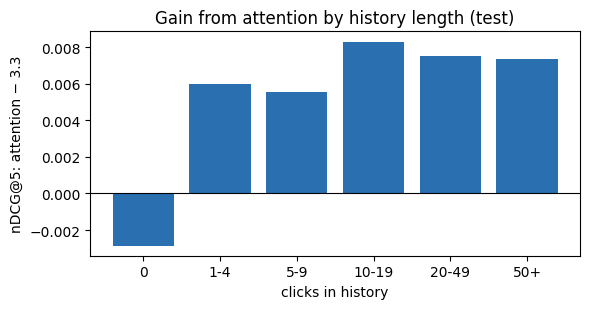

In [32]:
gain = per_imp[('mlp_attn', 'test')]['nDCG@5'].values - per_imp[('mlp_3.3', 'test')]['nDCG@5'].values
buckets = pd.cut(A['test']['hist_len'], [-1, 0, 4, 9, 19, 49, np.inf], labels=['0', '1-4', '5-9', '10-19', '20-49', '50+'])
by_length = pd.DataFrame({'clicks in history': buckets, 'gain': gain}) \
              .groupby('clicks in history', observed=False)['gain'].agg(nDCG5_gain='mean', impressions='size')
print(by_length.to_string())

plt.figure(figsize=(6, 3.2))
plt.bar(by_length.index.astype(str), by_length['nDCG5_gain'], color='#2a6fb0')
plt.axhline(0, color='black', lw=0.8)
plt.xlabel('clicks in history'); plt.ylabel('nDCG@5: attention − 3.3')
plt.title('Gain from attention by history length (test)')
plt.tight_layout(); plt.show()

### 9.2 By how varied a user's reading is
The reason for attention is users with mixed interests: an average blurs them, attention can pick the relevant part. Warm test users are split into three equal groups by `reading_entropy` (low = mostly one category, high = many categories). If the idea holds, the gain should be larger for the high-diversity group.

In [33]:
At = A['test']
warm = At['hist_len'] >= SPARSE_MAX
entropy = profiles['reading_entropy'].values[At['prof']][warm]
third = pd.qcut(pd.Series(entropy).rank(method='first'), 3, labels=['low diversity', 'medium', 'high diversity'])
by_diversity = pd.DataFrame({'reading diversity': third.values, 'entropy': entropy, 'gain': gain[warm]}) \
                 .groupby('reading diversity', observed=False) \
                 .agg(mean_entropy=('entropy', 'mean'), nDCG5_gain=('gain', 'mean'), impressions=('gain', 'size'))
by_diversity

,mean_entropy,nDCG5_gain,impressions
reading diversity,,,
low diversity,1.1820,0.0068,20949
medium,1.7003,0.0084,20948
high diversity,2.0524,0.0067,20949


### 9.3 One user, two candidates
A test user who reads at least 3 categories, and two candidates from different categories in the same impression. For each candidate, the three past clicks with the highest attention weight. If attention works, the top clicks change with the candidate (for example, sports clicks for a sports article). A single average vector cannot do this.

In [34]:
rng = np.random.default_rng(SEED)
example = None
for g in rng.permutation(len(At['n'])):
    clicks = HIST[At['prof'][g]]; clicks = clicks[clicks > 0]
    if len(clicks) < 10 or len(np.unique(art_cat[clicks])) < 3:
        continue
    s, k = At['start'][g], At['n'][g]
    pick = []
    for c in At['news'][s:s + k]:
        if art_cat[c] in set(art_cat[clicks]) and art_cat[c] not in [art_cat[x] for x in pick]:
            pick.append(c)
        if len(pick) == 2:
            example = (g, pick, clicks)
            break
    if example:
        break

if example is None:
    print('No suitable example found')
else:
    g, pick, clicks = example
    attn_model.eval()
    with torch.no_grad():
        w = attn_model.click_weights(torch.as_tensor([pick], device=device),
                                     torch.as_tensor([At['prof'][g]], device=device))[0].cpu().numpy()[:, :len(clicks)]
    mix = pd.Series([news_raw.loc[news_ids[n], 'category'] for n in clicks]).value_counts().to_dict()
    print(f"User {At['user_id'][g]}: {len(clicks)} clicks, categories {mix}\n")
    for j, c in enumerate(pick):
        print('Candidate:', describe(c))
        for i in np.argsort(-w[j])[:3]:
            print(f'   weight {w[j, i]:.3f}  {describe(clicks[i])}')
        print(f'   (equal weighting would give {1 / len(clicks):.3f} each)\n')

User U17508: 45 clicks, categories {'news': 12, 'sports': 7, 'lifestyle': 6, 'movies': 4, 'tv': 3, 'finance': 3, 'autos': 3, 'video': 3, 'health': 1, 'travel': 1, 'entertainment': 1, 'foodanddrink': 1}

Candidate: [news] Homeless woman living in SUV with dogs moves into apartment with commu
   weight 0.103  [movies] Kevin Spacey Won't Be Charged in Sexual Assault Case After Accuser Die
   weight 0.102  [news] One of FBI's Most Wanted fugitives offers surrender
   weight 0.098  [news] Felicity Huffman Is Scheduled to Be Released from Prison on October 27
   (equal weighting would give 0.022 each)

Candidate: [foodanddrink] Wendy's Is Turning 50 Years Old, And Is Gifting Us With Free Food Thro
   weight 0.092  [news] One of FBI's Most Wanted fugitives offers surrender
   weight 0.078  [tv] Lori Loughlin Is Facing New Charges in the College Admissions Scandal
   weight 0.075  [lifestyle] Jennifer Lopez Wore an Over-the-Top Sequined Slit Dress to Work
   (equal weighting would give 0.022 e

## 10. Save
* `attention_results.csv`: every model × split × user group, all metrics
* `bootstrap_test.csv`, `gain_by_history.csv`, `gain_by_diversity.csv`
* `predictions_test`, `prediction_test.txt`, `topk_test.csv`: the final model's test rankings, same format as 3.3
* `run_config.json`: settings used

In [35]:
results.to_csv(os.path.join(OUT_DIR, 'attention_results.csv'), index=False)
bootstrap.to_csv(os.path.join(OUT_DIR, 'bootstrap_test.csv'), index=False)
by_length.to_csv(os.path.join(OUT_DIR, 'gain_by_history.csv'))
by_diversity.to_csv(os.path.join(OUT_DIR, 'gain_by_diversity.csv'))

# test rankings of the final model (same files as 3.3)
At, sc = A['test'], scores[(FINAL, 'test')]
gid = np.repeat(np.arange(len(At['n'])), At['n'])
pred = pd.DataFrame({'impression_id': At['impression_id'][gid], 'orig_impression_id': At['orig_impression_id'][gid],
                     'source': At['source'][gid], 'user_id': At['user_id'][gid], 'news_id': news_ids[At['news']],
                     'slot': At['slot'], 'label': At['label'].astype(np.int8), 'score': sc.astype(np.float32),
                     'history_length': At['hist_len'][gid], 'is_cold_article': At['is_cold_article']})
pred['rank'] = pred.groupby('impression_id')['score'].rank(ascending=False, method='first').astype(np.int32)
try:
    pred.to_parquet(os.path.join(OUT_DIR, 'predictions_test.parquet'), index=False)
except ImportError:
    pred.to_pickle(os.path.join(OUT_DIR, 'predictions_test.pkl'))
pred = pred.sort_values(['impression_id', 'slot'])
with open(os.path.join(OUT_DIR, 'prediction_test.txt'), 'w') as f:
    for imp_id, r in pred.groupby('impression_id', sort=True)['rank']:
        f.write(f"{imp_id} [{','.join(map(str, r.values))}]\n")
top10 = (pred[pred['rank'] <= 10].sort_values(['impression_id', 'rank'])
         .groupby(['impression_id', 'user_id'])['news_id'].agg(' '.join).reset_index()
         .rename(columns={'news_id': 'top10_news_ids'}))
top10.to_csv(os.path.join(OUT_DIR, 'topk_test.csv'), index=False)

run_config = {'notebook': '3.4_mlp_attention', 'builds_on': ['3.1_mlp_feature_engineering', '3.3_mlp_model_improved'],
              'final_model': FINAL, 'selected_on_validation': BEST, 'cold_user_fallback': USE_FALLBACK,
              'best_epoch': {'mlp_3.3': int(baseline_hist.loc[baseline_hist['val_nDCG@5'].idxmax(), 'epoch']),
                             'mlp_attn': int(attn_hist.loc[attn_hist['val_nDCG@5'].idxmax(), 'epoch'])},
              'settings': {'seed': SEED, 'hidden': HIDDEN, 'embed_dim': EMBED_DIM, 'lr': LR, 'batch_size': BATCH_SIZE,
                           'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'cold_sim_rate': COLD_SIM_RATE,
                           'hist_len': HIST_LEN, 'att_hidden': ATT_HIDDEN, 'dropped_features': DROP_FEATURES},
              'features': active_features(CFG),
              'contract': {k: meta[k] for k in ['split', 'negative_sampling', 'cold_start', 'leakage', 'excluded_features']}}
with open(os.path.join(OUT_DIR, 'run_config.json'), 'w') as f:
    json.dump(run_config, f, indent=2, default=str)

print('Saved to', OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

Saved to /content/drive/MyDrive/BT4222/mlp_attn_out/
['attention_results.csv', 'bootstrap_test.csv', 'gain_by_diversity.csv', 'gain_by_history.csv', 'prediction_test.txt', 'predictions_test.parquet', 'run_config.json', 'runs', 'topk_test.csv']


## 11. Summary and limitations
**Result (seed 42, test day, full slates).** Adding attention over the last 50 clicks to Notebook 3.3's MLP raises nDCG@5 from 0.3506 to 0.3575 (+0.0069), MRR from 0.3194 to 0.3246 and Recall@5 from 0.4894 to 0.4989. The paired bootstrap puts the nDCG@5 gain between +0.0055 and +0.0082.

**Where it helps.** Warm users (+0.0073) and sparse users (+0.0060). The gain appears from the first few clicks and is similar for narrow and broad readers.

**Where it does not.** Cold users (no clicks to attend to; popularity ranks them best on test) and cold articles (slightly worse than Notebook 3.3's model).

**Limitations.**
* One training seed. Notebook 3.3's model scored 0.3600 in Notebook 3.3 (CPU) and 0.3506 when re-trained here (GPU), a gap larger than the attention gain; the bootstrap covers test-sample luck but not training randomness.
* Attention sees only the last 50 clicks; 75% of training impressions have their whole history within 50. Older clicks reach the model only through Notebook 3.3's average vector.
* Attention compares article content (text and category), not which other users clicked what.
* One test day (15 Nov 2019) of MIND-small, a one-week sample of MSN News.